# Amortized methods in geostatistics

In [1]:
import matplotlib
import matplotlib.pyplot as plt

import numpy as np

import random
from tqdm import tqdm
import time
import os

In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F

import torch_geometric
from torch_geometric.data import Data
from torch_geometric.nn import global_mean_pool, GCNConv

from torch_geometric.data import Dataset
from torch_geometric.loader import DataLoader
from torch_geometric.data import Batch

from torch_geometric.utils import to_scipy_sparse_matrix
from torch_geometric.nn.conv import MessagePassing
from torch_geometric.utils import scatter
from torch_geometric.nn import aggr

/home/aloret/PycharmProjects/Neural_ST_inference/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
from scipy.sparse.csgraph import connected_components
from scipy.spatial import cKDTree
from scipy.optimize import minimize
import scipy.linalg as linalg

In [4]:
import gstlearn as gl
import gstlearn.plot as gp
import gstlearn.document as gdoc
gdoc.setNoScroll()

<IPython.core.display.Javascript object>

In [5]:
device = torch.device("cuda:1" if torch.cuda.is_available() else "cpu")

## Simulation

### Sampling

In [6]:
def sampling_matern(lambdaParent,lambdaDaughter,radiusCluster):

    xMin = 0
    xMax = 1
    yMin = 0
    yMax = 1

    rExt = radiusCluster  
    xMinExt = xMin - rExt
    xMaxExt = xMax + rExt
    yMinExt = yMin - rExt
    yMaxExt = yMax + rExt

    xDeltaExt = xMaxExt - xMinExt
    yDeltaExt = yMaxExt - yMinExt
    areaTotalExt = xDeltaExt * yDeltaExt  

    numbPointsParent = np.random.poisson(areaTotalExt * lambdaParent)  
    
    xxParent = xMinExt + xDeltaExt * np.random.uniform(0, 1, numbPointsParent)
    yyParent = yMinExt + yDeltaExt * np.random.uniform(0, 1, numbPointsParent)

    numbPointsDaughter = np.random.poisson(lambdaDaughter, numbPointsParent) 
    numbPoints = sum(numbPointsDaughter)

    theta = 2 * np.pi * np.random.uniform(0, 1, numbPoints) 
    rho = radiusCluster * np.sqrt(np.random.uniform(0, 1, numbPoints)) 
    xx0 = rho * np.cos(theta)
    yy0 = rho * np.sin(theta)

    xx = np.repeat(xxParent, numbPointsDaughter)
    yy = np.repeat(yyParent, numbPointsDaughter)

    xx = xx + xx0
    yy = yy + yy0

    booleInside = ((xx >= xMin) & (xx <= xMax) & (yy >= yMin) & (yy <= yMax))
    xx = xx[booleInside]
    yy = yy[booleInside]

    # data = {'x1': xx, 'x2': yy}
    # sample = pd.DataFrame(data)

    sample = gl.Db()
    sample.addColumns(xx,"x1")
    sample.addColumns(yy,"x2")
    sample.setLocators(["x1","x2"],gl.ELoc.X)

    return sample


def grid():

    sample = gl.Db()
    sample.addColumns(np.repeat(np.linspace(0,1,100),100),"x1")
    sample.addColumns(np.tile(np.linspace(0,1,100),100),"x2")
    sample.setLocators(["x1","x2"],gl.ELoc.X)

    return sample 

theta_size = 2

In [7]:
def simulation_matern(sample, theta_range, theta_std, plot=False):

    model = gl.Model.createFromParam(type=gl.ECov.MATERN, range = theta_range*np.sqrt(8), param = 1, sill = theta_std**2)  # range is the practical range of Matérn with smoothness parameter = 1
    err = gl.simtub(None, sample, model, None, nbsimu=1, seed=0, nbtuba = 1000)

    if plot:
            fig, axs = plt.subplots(1, 1, figsize=(7, 7), constrained_layout=True)

            axs.scatter(sample['x1'], sample['x2'], c=sample['Simu'], s=8) 
        
            axs.set_xlabel('x1')
            axs.set_ylabel('x2')
            axs.set_title('Simu Values with Selected Points')

            axs.set_xlim([0, 1])
            axs.set_ylim([0, 1])
            axs.axis('equal')

            plt.show()

    return sample

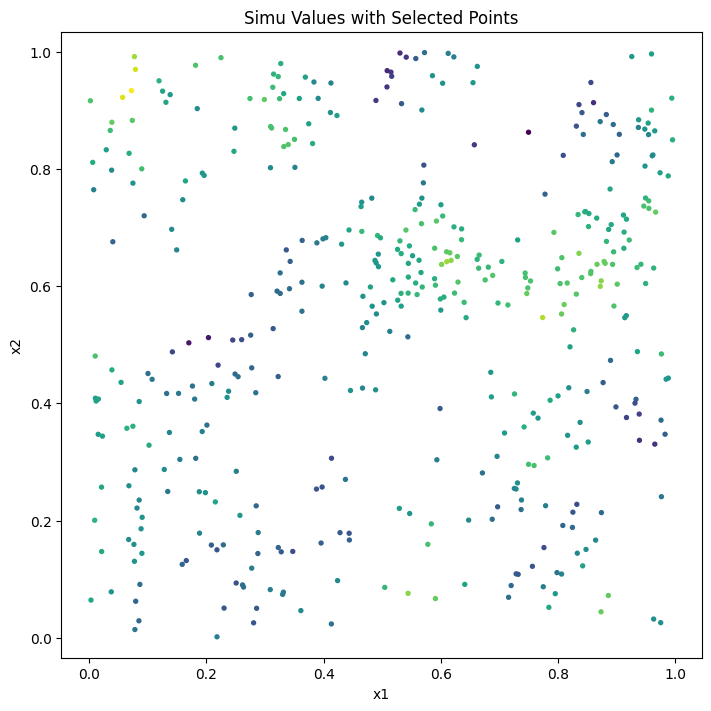


Data Base Characteristics

Data Base Summary
-----------------
File is organized as a set of isolated points
Space dimension              = 2
Number of Columns            = 3
Total number of samples      = 436

Variables
---------
Column = 0 - Name = x1 - Locator = x1
Column = 1 - Name = x2 - Locator = x2
Column = 2 - Name = Simu - Locator = z1

In [8]:
sample = sampling_matern(60,500//60,.1)
theta_range, theta_std = .1, 1.
simulation_matern(sample, theta_range, theta_std, plot=True)

In [9]:
def datamaker(constant_product, n, m, as_grid=False, range_min=.05, range_max=.5,std_min=.1, std_max=1.,lambdaParent_min=10,lambdaParent_max=60,radiusCluster = 0.15,log=False):

    datalist=[]

    range_list = np.random.uniform(range_min,range_max,m)
    std_list = np.random.uniform(std_min, std_max,m)
    lambdaParent = np.random.uniform(lambdaParent_min, lambdaParent_max,(n,m))
    lambdaDaughter = constant_product / lambdaParent

    print("i : ", end='')

    for i in range(n):

        print(i, end='|')

        # pi = torch.randperm(m)

        for j in range(m):

            if as_grid :
                sample = grid() 
            else :
                sample = sampling_matern(lambdaParent[i,j],lambdaDaughter[i,j],radiusCluster)
            simu = simulation_matern(sample, range_list[j], std_list[j])
    
            theta = (range_list[j], std_list[j])
    
            datalist.append((simu,theta,j))

    return datalist

In [10]:
n_points = 1000

n_train = 5
m_train = 5

n_test = 5
m_test = 5

batch_size = 20 

In [11]:
sampling_train = datamaker(n_points, n_train,m_train, as_grid=False)

i : 0|1|2|3|4|

In [12]:
sampling_test = datamaker(n_points, n_test, m_test, as_grid=False)

i : 0|1|2|3|4|

### Graphs

In [13]:
def create_edge_graph(sample, threshold=.4, max_neighbors=10):
    coords = sample[['x1', 'x2']]
    node_features = torch.tensor(sample[['Simu']], dtype=torch.float)

    nearest_neighbors = cKDTree(coords) 

    edge_sources = []
    edge_destinations = []
    edge_features = []

    for i, coord in enumerate(coords):
        neighbors = nearest_neighbors.query_ball_point(coord, r=threshold)
        neighbors = [j for j in neighbors if j != i]

        if len(neighbors) > max_neighbors:
            neighbors = np.random.choice(neighbors, max_neighbors, replace=False)

        dists = np.linalg.norm(coords[neighbors] - coord, axis=1)
            
        edge_sources.extend(np.repeat(i,len(neighbors))) # [i] * len(neighbors)
        edge_destinations.extend(neighbors) # neighbors.tolist()

        edge_sources.extend(neighbors)
        edge_destinations.extend(np.repeat(i,len(neighbors)))
        
        edge_features.extend(np.concatenate([dists, dists]))

    edge_index = torch.tensor([edge_sources, edge_destinations], dtype=torch.long)
    edge_attr = torch.tensor(edge_features, dtype=torch.float).unsqueeze(1) # .view(-1, 1)

    return Data(x=node_features.unsqueeze(-1), edge_index=edge_index, edge_attr=edge_attr)# sizes=len(node_features))


In [14]:
class GraphDataset(Dataset):
    def __init__(self, datalist):
        self.datalist = datalist

    def __len__(self):
        return len(self.datalist)

    def __getitem__(self, idx):
        return self.datalist[idx]

In [15]:
def datamaker_graph(simu, threshold = 0.4,max_neighbors = 5):

    n = len(simu)
    datalist = []

    t = tqdm(range(0, n),total=n)

    for i in t:
        
        data = create_edge_graph(simu[i][0], threshold, max_neighbors)
        theta = torch.tensor(simu[i][1])
        deepset = torch.tensor(simu[i][2])

        datalist.append((data, theta, deepset))

    return GraphDataset(datalist)

In [16]:
dataset_graph = datamaker_graph(sampling_train)
loader_graph = DataLoader(dataset_graph, batch_size, shuffle=True)

dataset_graph_test = datamaker_graph(sampling_test)
loader_graph_test = DataLoader(dataset_graph_test, len(sampling_test), shuffle=False)

dataset_graph[2]

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 25/25 [00:01<00:00, 15.94it/s]


(Data(x=[686, 1], edge_index=[2, 6860], edge_attr=[6860, 1]),
 tensor([0.2423, 0.4705], dtype=torch.float64),
 tensor(2))

### Grid

In [17]:
def points_to_grid(sample, nb_bins=100):
    
    bin_size = 1.0 / nb_bins

    x1 = torch.tensor(sample['x1'], dtype=torch.float32)
    x2 = torch.tensor(sample['x2'], dtype=torch.float32)
    values = torch.tensor(sample['Simu'], dtype=torch.float32)
    
    ix = torch.clamp((x1 / bin_size).long(), max=nb_bins - 1)
    iy = torch.clamp((x2 / bin_size).long(), max=nb_bins - 1)

    flat_idx = ix * nb_bins + iy
    
    # value_flat = torch.zeros(nb_bins * nb_bins, dtype=torch.float32)
    # count_flat = torch.zeros(nb_bins * nb_bins, dtype=torch.float32)
        
    # value_flat.index_add_(0, flat_idx, values)
    # count_flat.index_add_(0, flat_idx, torch.ones_like(values))

    # mean_grid = torch.empty_like(value_flat)
    # mean_grid[:] = float('nan')
    # mask = count_flat > 0
    # mean_grid[mask] = value_flat[mask] / count_flat[mask]

    # return mean_grid.view(nb_bins, nb_bins)

    value_flat = torch.full((nb_bins * nb_bins,), float('nan'))

    unique_idx = flat_idx.unique()
    for idx in unique_idx:
        indices_in_cell = torch.where(flat_idx == idx)[0]
        chosen = indices_in_cell[torch.randint(0, len(indices_in_cell), (1,))]
        value_flat[idx] = values[chosen]

    return value_flat.view(nb_bins, nb_bins)

In [18]:
class GridSetDataset(Dataset):
    def __init__(self, datalist):
        self.datalist = datalist

    def __len__(self):
        return len(self.datalist)

    def __getitem__(self, idx):
                
        data = self.datalist[idx][0]
        mask = (~torch.isnan(data)).float()
        
        data = torch.nan_to_num(data, nan=0.)
        
        data = torch.stack([data, mask], dim=0) 
        # data = data.unsqueeze(0)
        
        theta = self.datalist[idx][1]

        deepset = self.datalist[idx][2]
        
        return data, theta, deepset

In [19]:
def datamaker_grid(simu,bins = 100):

    n = len(simu)
    datalist = []
    
    t = tqdm(range(0, n),total=n)
    
    for i in t:

        data = points_to_grid(simu[i][0], bins)
        theta = torch.tensor(simu[i][1])
        deepset = torch.tensor(simu[i][2])
        
        datalist.append((data, theta,deepset))               
    
    return GridSetDataset(datalist)

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 25/25 [00:00<00:00, 48.11it/s]


tensor([0.2423, 0.4705], dtype=torch.float64) tensor(2)


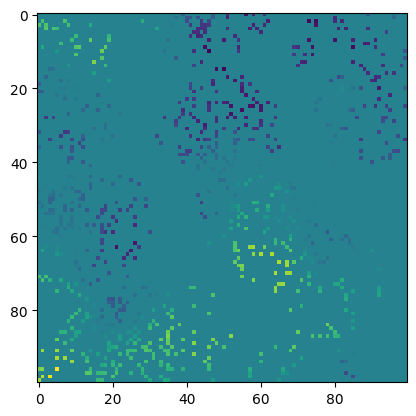

In [20]:
dataset_grid = datamaker_grid(sampling_train)
loader_grid = DataLoader(dataset_grid, batch_size, shuffle=True)

dataset_grid_test = datamaker_grid(sampling_test)
loader_grid_test = DataLoader(dataset_grid_test, len(sampling_test), shuffle=False)

plt.imshow(dataset_grid[7][0][0])
print(dataset_grid[7][1], dataset_grid[7][2])

## Save and Load

In [6]:
file = "data/data2"

os.makedirs(file, exist_ok=True)
os.makedirs(file+"/samples", exist_ok=True)

In [34]:
batch_size = 20

train_grid = torch.load(file+"/train_grid.pt")
train_graph = torch.load(file+"/train_graph.pt", weights_only=False)
train_theta = torch.load(file+"/train_theta.pt")
train_deepset = torch.load(file+"/train_deepset.pt")

nm_train = len(train_theta)
m_train = len(train_deepset.unique())
n_train = nm_train // m_train

dataset_grid = [(train_grid[i], train_theta[i], train_deepset[i]) for i in range(nm_train)]
dataset_graph = [(train_graph[i], train_theta[i], train_deepset[i]) for i in range(nm_train)]
sampling_train = [(gl.Db.createFromNF(file+"/samples/sample_train"+str(i)), train_theta[i], train_deepset[i]) for i in range(nm_train)]

###

test_grid = torch.load(file+"/test_grid.pt")
test_graph = torch.load(file+"/test_graph.pt", weights_only=False)
test_theta = torch.load(file+"/test_theta.pt")
test_deepset = torch.load(file+"/test_deepset.pt")

nm_test = len(test_theta)
m_test = len(test_deepset.unique())
n_test = nm_test // m_test

dataset_grid_test = [(test_grid[i], test_theta[i], test_deepset[i]) for i in range(nm_test)]
dataset_graph_test = [(test_graph[i], test_theta[i], test_deepset[i]) for i in range(nm_test)]
sampling_test = [(gl.Db.createFromNF(file+"/samples/sample_test"+str(i)), test_theta[i], test_deepset[i]) for i in range(nm_test)]

###

loader_graph = DataLoader(dataset_graph, batch_size, shuffle=True)
loader_graph_test = DataLoader(dataset_graph_test, nm_test, shuffle=False)

loader_grid = DataLoader(dataset_grid, batch_size, shuffle=True)
loader_grid_test = DataLoader(dataset_grid_test, nm_test, shuffle=False)

In [8]:
dataset_graph[2]

(Data(x=[686, 1], edge_index=[2, 6860], edge_attr=[6860, 1]),
 tensor([0.2423, 0.4705], dtype=torch.float64),
 tensor(2))

tensor([0.2423, 0.4705], dtype=torch.float64) tensor(2)


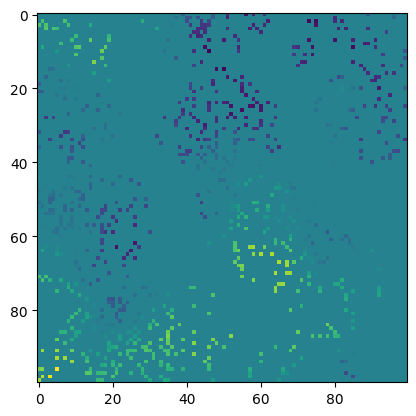

In [9]:
plt.imshow(dataset_grid[7][0][0])
print(dataset_grid[7][1], dataset_grid[7][2])

In [28]:
print(sampling_train[1][0])


Data Base Characteristics

Data Base Summary
-----------------
File is organized as a set of isolated points
Space dimension              = 2
Number of Columns            = 3
Total number of samples      = 619

Variables
---------
Column = 0 - Name = x1 - Locator = x1
Column = 1 - Name = x2 - Locator = x2
Column = 2 - Name = Simu - Locator = z1



## Utils

In [11]:
def unique_preserve_order(x):
    seen = []
    out = []
    for v in x.tolist():
        if v not in seen:
            seen.append(v)
            out.append(v)
    return torch.tensor(out, device=x.device)


def map_deepset(deepset, theta):
    unique_ds = unique_preserve_order(deepset)

    deepset_mapped = torch.tensor(
        [unique_ds.tolist().index(int(ds)) for ds in deepset],
        device=device
    )

    theta = torch.stack([theta[deepset == v][0] for v in unique_ds])

    return deepset_mapped, theta

In [30]:
def baseline_mae(dataset):
    all_thetas = torch.stack([data[1] for data in dataset])
    
    theta_mean = all_thetas.mean(dim=0) 
    
    preds = theta_mean.unsqueeze(0).repeat(len(dataset), 1)
    
    mae = torch.mean(torch.abs(preds - all_thetas),dim=0)

    return mae, theta_mean

theta_size = 2

## GNN

In [13]:
class GNN_network(nn.Module):
    def __init__(self, in_channels=1, hidden=32, out_dim=2, nls=False):
        super().__init__()

        self.nls = nls

        self.conv1 = GCNConv(in_channels, hidden)
        self.conv2 = GCNConv(hidden, hidden)

        self.readout_dim = hidden 

        self.dense = nn.Sequential(
            nn.Linear(hidden+2*nls, 32),
            nn.ReLU(),
            nn.Linear(32, out_dim)  
        )

    def forward(self, data, deepset=None, theta=None):
        x = F.relu(self.conv1(data.x, data.edge_index))
        x = F.relu(self.conv2(x, data.edge_index))

        x = global_mean_pool(x, data.batch)     # [batch_size, hidden_dim]

        if not self.nls :
            x = global_mean_pool(x, deepset)   # [nb_deepset, hidden_dim]
        else :
            x = torch.cat((x, theta.float()),dim=1)

        out = self.dense(x)
        return out 


In [14]:
def train_gnn(model, optimizer, loader):
    
    model.train()
    MAE = torch.nn.L1Loss(reduction="mean")
    
    sum_loss = []

    for i, (batched_data, theta, deepset) in enumerate(loader):
        optimizer.zero_grad()

        batched_data, theta, deepset = batched_data.to(device), theta.to(device), deepset.to(device)

        deepset_mapped, theta = map_deepset(deepset, theta)

        output = model(batched_data, deepset_mapped)
        
        batch_loss = MAE(output, theta)
        
        batch_loss.backward()
        optimizer.step()

        sum_loss.append(torch.abs(output - theta))

    return torch.cat(sum_loss,dim=0)



In [15]:
model_graph = GNN_network(in_channels=1)

optimizer_graph = torch.optim.Adam(model_graph.parameters(), lr=1e-4)

In [16]:
n_epochs = 50
n_epochs_test = 10
all_loss_train_graph = [] # torch.zeros((n_epochs, n_train,theta_size))
all_loss_test_graph = [] # torch.zeros((n_epochs//n_epochs_test, n_test,theta_size))

t = tqdm(range(0, n_epochs),total=n_epochs)

time_train_graph = time.time()

for epoch in t:
    
    loss = train_gnn(
        model_graph,
        optimizer_graph,
        loader_graph,
    )

    t.set_description(f"Epoch {epoch+1}/{n_epochs}")
    t.set_postfix(loss=f"{loss.mean(dim=0)}")
    all_loss_train_graph.append(loss.detach().numpy())

    # test
    if (epoch+1)%n_epochs_test == 0 :
        time_test_graph = time.time()
        for data_test, theta_test, deepset_test in loader_graph_test : 
            deepset_mapped_test, theta_test = map_deepset(deepset_test, theta_test)
            output = model_graph(data_test,deepset_mapped_test)
            l = torch.abs(output - theta_test)
        time_test_graph = time.time() - time_test_graph
        time_train_graph -= time_test_graph
        all_loss_test_graph.append(l.detach().numpy())

time_train_graph = time.time() - time_train_graph

print(f"Time to train : {time_train_graph:.2f}s")

# all_loss_train_graph = torch.stack(all_loss_train_graph).detach().numpy()
# all_loss_test_graph = torch.stack(all_loss_test_graph).detach().numpy()
print("Train loss :", np.mean(all_loss_train_graph[-1],axis=0), "±", np.std(all_loss_train_graph[-1],axis=0))
print("Test loss :", np.mean(all_loss_test_graph[-1],axis=0), "±", np.std(all_loss_test_graph[-1],axis=0))

Epoch 50/50: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 50/50 [00:04<00:00, 11.69it/s, loss=tensor([0.2579, 0.5927], dtype=torch.float64, grad_fn=<MeanBackward1>)]

Time to train : 4.56s
Train loss : [0.25786658 0.59271086] ± [0.14641934 0.20789303]
Test loss : [0.08339574 0.7091869 ] ± [0.03317161 0.2120898 ]


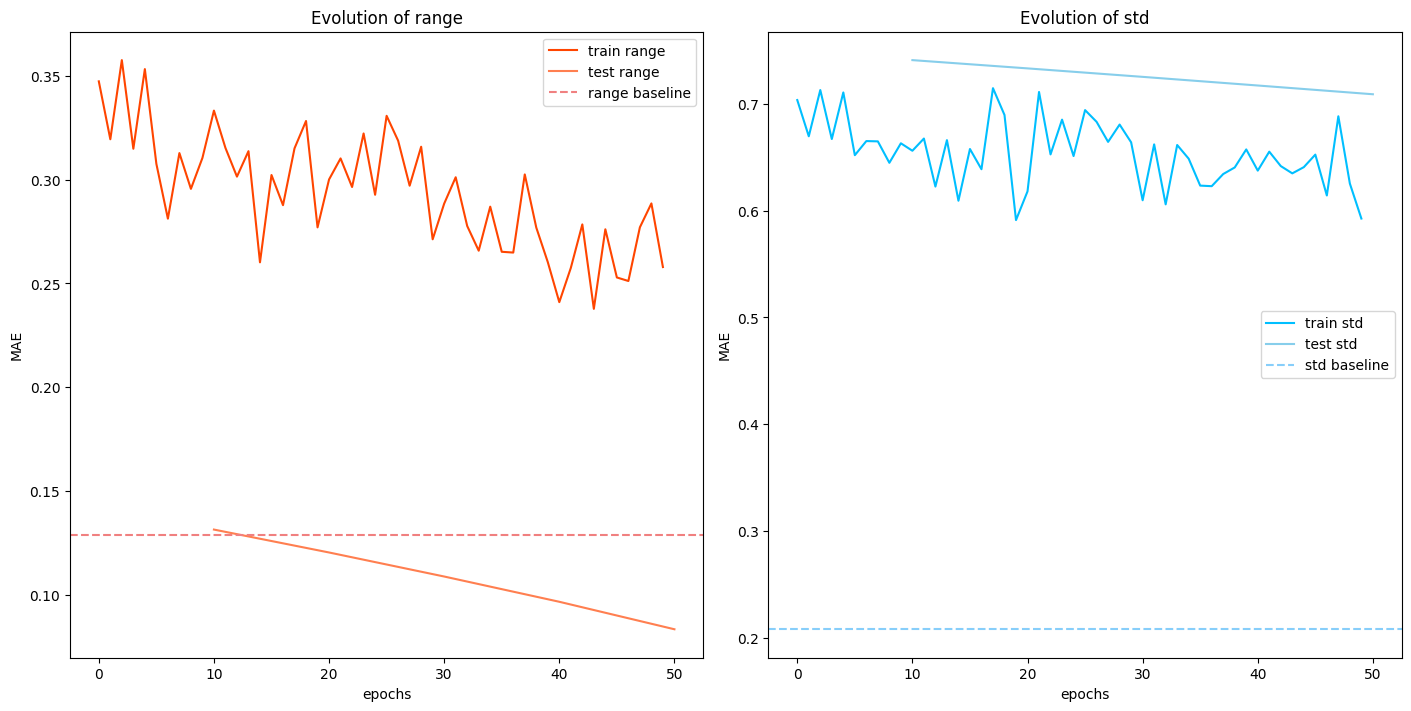

In [51]:
fig_gnn, ax = plt.subplots(1, 2, figsize=(14, 7), constrained_layout=True)
ax[0].plot([l.mean(axis=0)[0] for l in all_loss_train_graph], 'orangered', label='train range')
ax[1].plot([l.mean(axis=0)[1] for l in all_loss_train_graph], 'deepskyblue',label='train std')
ax[0].plot(np.arange(n_epochs_test,n_epochs+1,n_epochs_test),[l.mean(axis=0)[0] for l in all_loss_test_graph], 'coral', label='test range')
ax[1].plot(np.arange(n_epochs_test,n_epochs+1,n_epochs_test),[l.mean(axis=0)[1] for l in all_loss_test_graph], 'skyblue',label='test std')

based, _ = baseline_mae(dataset_graph)
ax[0].axhline(based[0],color='lightcoral', ls='--', label='range baseline')
plt.axhline(based[1],color='lightskyblue', ls='--', label='std baseline')

ax[0].set_title('Evolution of range')
ax[1].set_title('Evolution of std')
ax[0].set_xlabel('epochs')
ax[1].set_xlabel('epochs')
ax[0].set_ylabel('MAE')
ax[1].set_ylabel('MAE')
ax[0].legend()
ax[1].legend()

## CNN

In [18]:
class CNN_network(nn.Module):
    def __init__(self, in_channels=2, hidden=32, out_dim=2, nls=False):
        super().__init__()

        self.nls = nls
        
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, hidden, 10, padding=1),
            nn.ReLU(),
            nn.Conv2d(hidden, hidden, 5, padding=1),
            nn.ReLU(),
        )
        
        self.pool = nn.AdaptiveAvgPool2d(1) 
        
        self.dense = nn.Sequential(
            nn.Linear(hidden+2*nls, 32),
            nn.ReLU(),
            nn.Linear(32, out_dim)  
        )

    def forward(self, x, deepset=None, theta=None):
        h = self.conv(x)
        h = self.pool(h).view(h.shape[0], -1)

        if not self.nls :
            h = global_mean_pool(h, deepset)   # [nb_deepset, hidden_dim]
        else :
            h = torch.cat((h, theta.float()),dim=1)
        
        out = self.dense(h)
        return out

class CNN_network_nodense(nn.Module):
    def __init__(self, in_channels=2, hidden=32, out_dim=2):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, hidden, 3, padding=1),
            nn.ReLU(),
            nn.Conv2d(hidden, hidden, 3, padding=1),
            nn.ReLU(),
        )
        self.pool = nn.AdaptiveAvgPool2d(16)
        self.conv_out = nn.Sequential(
            nn.Conv2d(hidden, hidden//2, 4, padding=0,stride=4),
            nn.ReLU(),
            nn.Conv2d(hidden//2, 2, 4, padding=0,stride=4)
        )

    def forward(self, x, deepset):
        
        h = self.conv(x)
        
        h = self.pool(h)

        h_shape = torch.tensor(h.shape)
            
        h = global_mean_pool(h.reshape((h_shape[0], -1)), deepset)   # [nb_deepset, hidden_dim]

        h = h.view(h.size(0), h_shape[1], h_shape[2], h_shape[3])
        out = self.conv_out(h)
        out = out.view(h.shape[0], -1)
        
        return out

In [19]:
def train_cnn(model, optimizer, loader):
    
    model.train()
    MAE = torch.nn.L1Loss(reduction="mean")
    
    sum_loss = []

    for i, (batched_data, theta, deepset) in enumerate(loader):
        optimizer.zero_grad()

        batched_data, theta, deepset = batched_data.to(device), theta.to(device), deepset.to(device)

        deepset_mapped, theta = map_deepset(deepset, theta)
        
        output = model(batched_data, deepset_mapped)
        
        batch_loss = MAE(output, theta)
        
        batch_loss.backward()
        optimizer.step()

        sum_loss.append(torch.abs(output - theta))

    return torch.cat(sum_loss,dim=0)


In [20]:
model_grid = CNN_network(in_channels=2).to(device)

optimizer_grid = torch.optim.Adam(model_grid.parameters(), lr=1e-4)

In [21]:
n_epochs = 50
n_epochs_test = 10
all_loss_train_grid = [] # torch.zeros((n_epochs, n_train,theta_size))
all_loss_test_grid = [] # torch.zeros((n_epochs//n_epochs_test, n_test,theta_size))

t = tqdm(range(0, n_epochs),total=n_epochs)

time_train_grid = time.time()

for epoch in t:
    
    loss = train_cnn(
        model_grid,
        optimizer_grid,
        loader_grid,
    )

    t.set_description(f"Epoch {epoch+1}/{n_epochs}")
    t.set_postfix(loss=f"{loss.mean(dim=0)}")
    all_loss_train_grid.append(loss.detach().numpy())

    # test
    if (epoch+1)%n_epochs_test == 0 :
        time_test_grid = time.time()
        for data_test, theta_test, deepset_test in loader_grid_test : 
            deepset_mapped_test, theta_test = map_deepset(deepset_test, theta_test)
            output = model_grid(data_test,deepset_mapped_test)
            l = torch.abs(output - theta_test.unique(dim=0, sorted=False))
        time_test_grid = time.time() - time_test_grid
        time_train_grid -= time_test_grid
        all_loss_test_grid.append(l.detach().numpy())

time_train_grid = time.time() - time_train_grid

print(f"Time to train : {time_train_grid:.2f}s")

print("Train loss :", np.mean(all_loss_train_grid[-1],axis=0), "±", np.std(all_loss_train_grid[-1],axis=0))
print("Test loss :", np.mean(all_loss_test_grid[-1],axis=0), "±", np.std(all_loss_test_grid[-1],axis=0))

Epoch 50/50: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 50/50 [00:08<00:00,  6.22it/s, loss=tensor([0.1403, 0.1737], dtype=torch.float64, grad_fn=<MeanBackward1>)]

Time to train : 8.35s
Train loss : [0.14034212 0.17372402] ± [0.10658098 0.12839554]
Test loss : [0.12211493 0.2202608 ] ± [0.04981733 0.11890685]


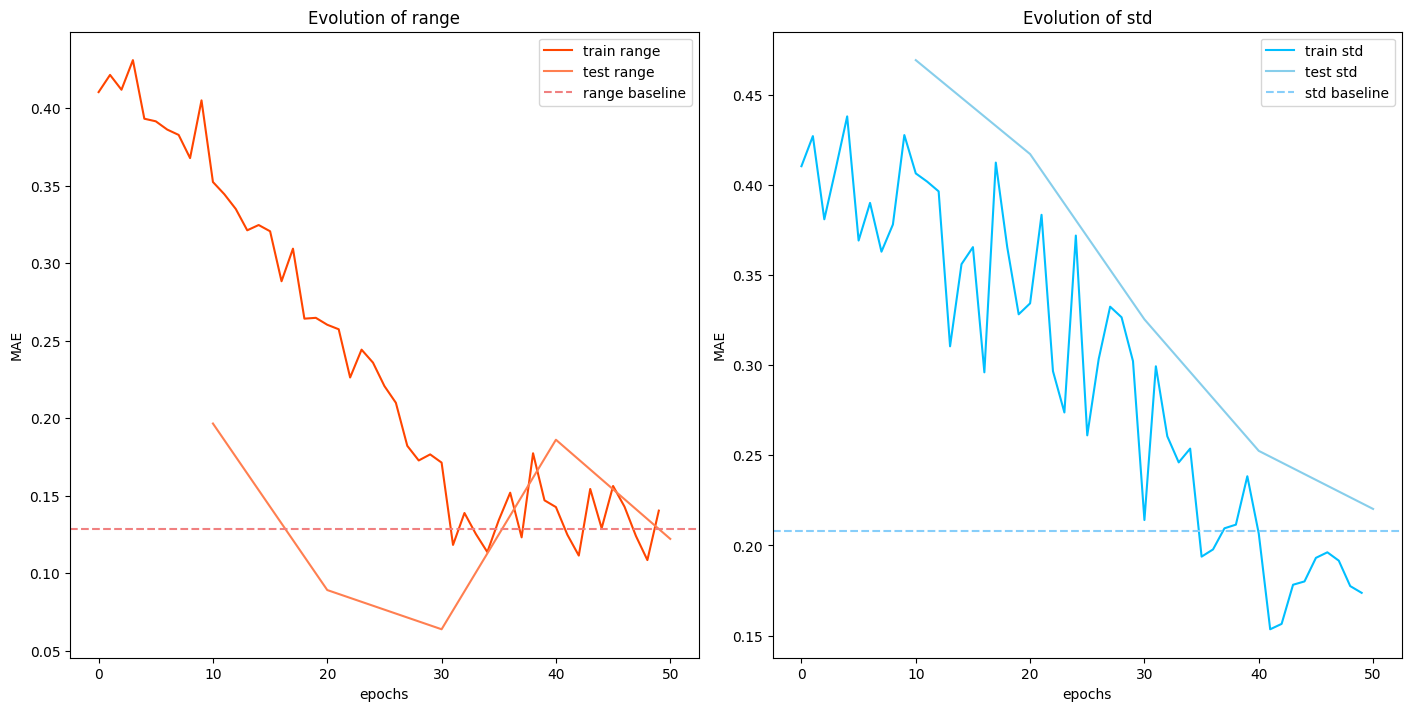

In [50]:
fig_cnn, ax = plt.subplots(1, 2, figsize=(14, 7), constrained_layout=True)
ax[0].plot([l.mean(axis=0)[0] for l in all_loss_train_grid], 'orangered', label='train range')
ax[1].plot([l.mean(axis=0)[1] for l in all_loss_train_grid], 'deepskyblue',label='train std')
ax[0].plot(np.arange(n_epochs_test,n_epochs+1,n_epochs_test),[l.mean(axis=0)[0] for l in all_loss_test_grid], 'coral', label='test range')
ax[1].plot(np.arange(n_epochs_test,n_epochs+1,n_epochs_test),[l.mean(axis=0)[1] for l in all_loss_test_grid], 'skyblue',label='test std')

based, _ = baseline_mae(dataset_grid)
ax[0].axhline(based[0],color='lightcoral', ls='--', label='range baseline')
plt.axhline(based[1],color='lightskyblue', ls='--', label='std baseline')

ax[0].set_title('Evolution of range')
ax[1].set_title('Evolution of std')
ax[0].set_xlabel('epochs')
ax[1].set_xlabel('epochs')
ax[0].set_ylabel('MAE')
ax[1].set_ylabel('MAE')
ax[0].legend()
ax[1].legend()

## Maximum likelyhood

In [55]:
def matern_covariance_from_coords(coords, range_theta, std_theta):
    db = gl.Db()
    db.addColumns(coords[:,0],"x1")
    db.addColumns(coords[:,1],"x2")
    db.setLocators(["x1","x2"],gl.ELoc.X)

    model = gl.Model.createFromParam(
        type=gl.ECov.MATERN,
        range=range_theta* np.sqrt(8),
        sill=std_theta**2,
        param=1.
    )

    cov = gl.evalCovMatSym(model,db)

    vals = cov.getValues()
    cov_np = np.array(vals).reshape(cov.getNRows(), cov.getNCols())

    return cov_np

In [56]:
def nll(theta, coords, values, eps=1e-6): 
    # https://soft.mines-paristech.fr/gstlearn/demos-latest/python/Tuto_LogLikelihood.html

    range_theta, std_theta = theta
    cov = matern_covariance_from_coords(coords, range_theta, std_theta)
    cov += eps * np.eye(cov.shape[0])

    L = linalg.cholesky(cov) 

    # solve Σ^{-1} @ values 
    alpha = linalg.cho_solve((L, False), values) 

    # Compute values.T @ Σ^{-1} @ values 
    quad = float(np.dot(values,alpha))

    # det term, https://math.stackexchange.com/questions/3158303/using-cholesky-decomposition-to-compute-covariance-matrix-determinant
    logdet = 2.0 * np.sum(np.log(np.diag(L)))

    return 0.5 * (logdet + quad + values.size * np.log(2.0 * np.pi))

In [69]:
def mle_matern(coords, values, theta0=(.2, .5)):

    def obj(theta):
        return nll(theta, coords, values)

        # db = gl.Db()
        # db.addColumns(coords[:,0],"x1")
        # db.addColumns(coords[:,1],"x2")
        # db.setLocators(["x1","x2"],gl.ELoc.X)
        # db.addColumns(values, "Simu")
    
        # model = gl.Model.createFromParam(
        #     type=gl.ECov.MATERN,
        #     range=theta[0]* np.sqrt(8),
        #     sill=theta[1]**2,
        #     param=1.
        # )

        # res = model.computeLogLikelihood(db, True)

        # return res
        

    res = minimize(obj, theta0, method="Nelder-Mead", options={"maxiter":2000})
    return res.x, res

In [ ]:
all_loss_test_ML = np.zeros((len(sampling_test),theta_size))

time_test_ML = time.time()

for i, (data_test, theta_test, _) in enumerate(sampling_test) : 

    output, _ = mle_matern(data_test[["x1","x2"]],data_test["Simu"])

    all_loss_test_ML[i] = np.abs(output - np.array(theta_test))

    print(f"| RANGE {output[0]:.4f} - {theta_test[0]:.4f} = {abs(output[0]-theta_test[0]):.4f} | STD {output[1]:.4f} - {theta_test[1]:.4f} = {abs(output[1]-theta_test[1]):.4f} |")

time_test_ML = time.time() - time_test_ML

print(f"\nTime to test : {time_test_ML:.2f}s")

print("Test loss :", np.mean(all_loss_test_ML,axis=0), "±", np.std(all_loss_test_ML,axis=0))

## NLS

In [37]:
dataset_graph_perm = []
dataset_graph_noperm = []

for i in range(n_train):
    pi = torch.randperm(m_train) # attention deepset

    dataset_graph_perm += [(dataset_graph[j + i*m_train][0], dataset_graph[pi[j]][1], torch.tensor(0)) for j in range(m_train) ]
    dataset_graph_noperm += [(dataset_graph[j + i*m_train][0], dataset_graph[j][1], torch.tensor(1)) for j in range(m_train)]

dataset_graph_nls = dataset_graph_perm + dataset_graph_noperm

loader_graph_nls = DataLoader(dataset_graph_nls, batch_size, shuffle=True)

In [38]:
dataset_grid_perm = []
dataset_grid_noperm = []

for i in range(n_train):
    pi = torch.randperm(m_train) # attention deepset

    dataset_grid_perm += [(dataset_grid[j + i*m_train][0], dataset_grid[pi[j]][1], torch.tensor(0)) for j in range(m_train) ]
    dataset_grid_noperm += [(dataset_grid[j + i*m_train][0], dataset_grid[j][1], torch.tensor(1)) for j in range(m_train)]

dataset_grid_nls = dataset_grid_perm + dataset_grid_noperm

loader_grid_nls = DataLoader(dataset_grid_nls, batch_size, shuffle=True)

In [39]:
def train_nls(model, optimizer, loader):
    
    model.train()
    CE = nn.CrossEntropyLoss() # torch.nn.BCELoss(reduction="mean") 
    
    sum_loss = []

    for i, (x, theta, classi) in enumerate(loader):
        optimizer.zero_grad()

        x, theta, label = x.to(device), theta.to(device), classi.to(device).flatten()

        # print(x.shape, theta, classi)

        output = model(x, theta=theta)
        
        batch_loss = CE(output, label)
        
        batch_loss.backward()
        optimizer.step()
        
        sum_loss.append(batch_loss.item())

    return sum_loss

In [40]:
model_nls = GNN_network(in_channels=1, nls=True).to(device)
# model_nls = CNN_network(in_channels=2, nls=True).to(device)

optimizer_nls = torch.optim.Adam(model_nls.parameters(), lr=1e-3)

Epoch 50/50: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 50/50 [00:06<00:00,  7.52it/s, loss=0.6792961160341898]

Time to train : 6.65s


Text(0, 0.5, 'Cross Entropy')

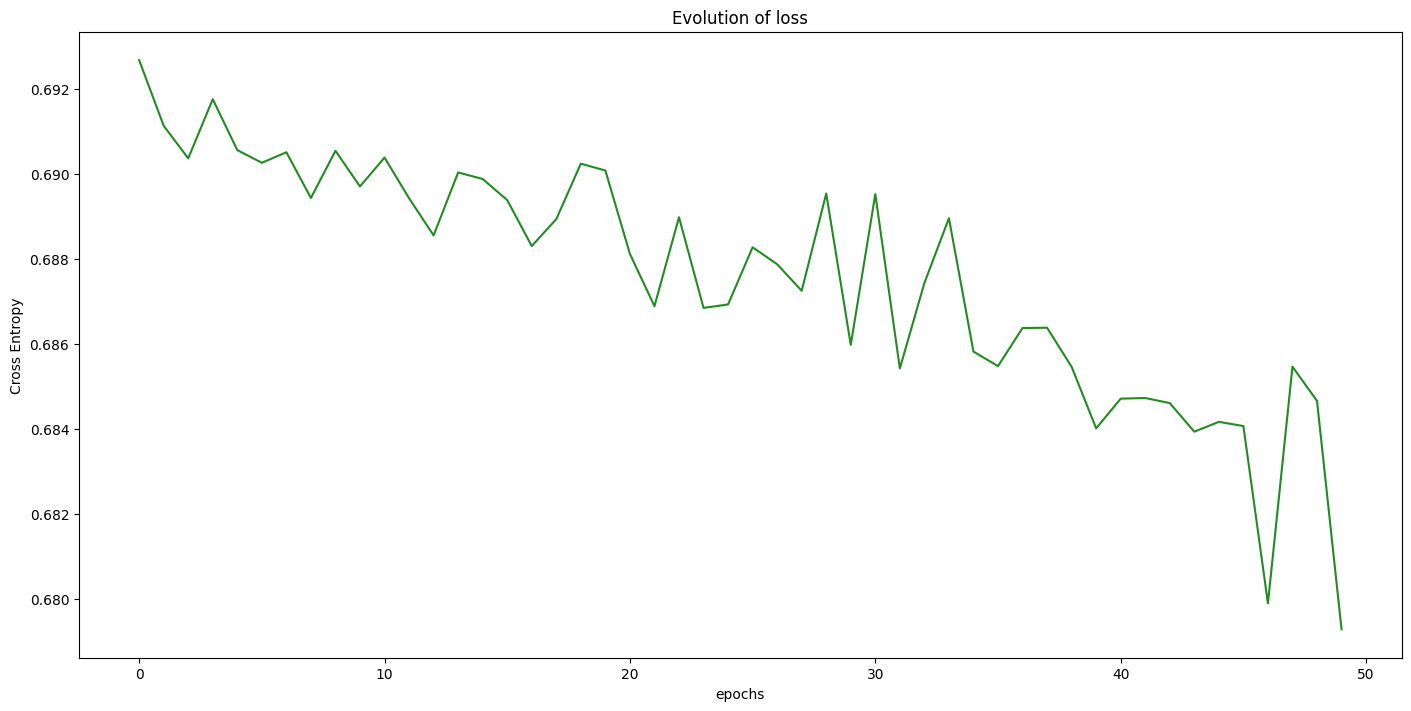

In [54]:
n_epochs = 50
all_loss_train_nls=np.zeros((n_epochs,))

t = tqdm(range(0, n_epochs),total=n_epochs)

time_train_nls = time.time()

for epoch in t:
    
    loss = train_nls(
        model_nls,
        optimizer_nls,
        loader_graph_nls,
    )

    t.set_description(f"Epoch {epoch+1}/{n_epochs}")
    t.set_postfix(loss=f"{np.mean(loss)}")
    all_loss_train_nls[epoch] = np.mean(loss)

time_train_nls = time.time() - time_train_nls

print(f"Time to train : {time_train_nls:.2f}s")

fig_nls, ax = plt.subplots(1, 1, figsize=(14, 7), constrained_layout=True)
ax.plot(all_loss_train_nls, 'forestgreen')

ax.set_title('Evolution of loss')
ax.set_xlabel('epochs')
ax.set_ylabel('Cross Entropy')

In [42]:
def estimate_likelihood_surface(model, simu, theta_grid):
    
    model.eval()
    
    L_values = []
    simu = simu.to(device)
    
    with torch.no_grad():
        t = tqdm(theta_grid)
        for theta in t:
            
            theta_t = torch.tensor(theta, dtype=torch.float32).unsqueeze(0).tile((m_test*n_test, 1)).to(device)
            
            h = model(simu, theta=theta_t)
            p = torch.softmax(h, dim=1)[:, 1] 
            
            L = p / (1 - p)
            L_values.append(L)
            
    return torch.stack(L_values)

In [43]:
range_min, range_max = 0.05, 0.5
std_min, std_max = 0.1, 1.0

n_range = 10
n_std = 10

range_vals = torch.linspace(range_min, range_max, n_range)
std_vals = torch.linspace(std_min, std_max, n_std)

R, S = torch.meshgrid(range_vals, std_vals, indexing='ij')
theta_grid = torch.stack([R.flatten(), S.flatten()], dim=1)

In [44]:
time_test_nls = time.time()

for data_test, theta_test, _ in loader_graph_test : 
    L_values = estimate_likelihood_surface(model_nls, data_test, theta_grid)
    output = theta_grid[torch.argmax(L_values,dim=0)]
    all_loss_test_nls = torch.abs(output - theta_test).detach().numpy()
    
time_test_nls = time.time() - time_test_nls

print(f"\nTime to test : {time_test_nls:.2f}s")

print("Test loss :", np.mean(all_loss_test_nls,axis=0), "±", np.std(all_loss_test_nls,axis=0))

  0%|                                                                                                                                                                                                                                                                                       | 0/100 [00:00<?, ?it/s]/tmp/ipykernel_823936/2006245510.py:12: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  theta_t = torch.tensor(theta, dtype=torch.float32).unsqueeze(0).tile((m_test*n_test, 1)).to(device)
100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 100/100 [00:03<00:00, 31.84it/s]


Time to test : 3.15s
Test loss : [0.12715978 0.48769461] ± [0.10551366 0.21278884]


## Conclusion

/tmp/ipykernel_823936/669821274.py:16: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axs[0].boxplot(loss_range, labels=methods, patch_artist=True,
/tmp/ipykernel_823936/669821274.py:22: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axs[1].boxplot(loss_std, labels=methods, patch_artist=True,


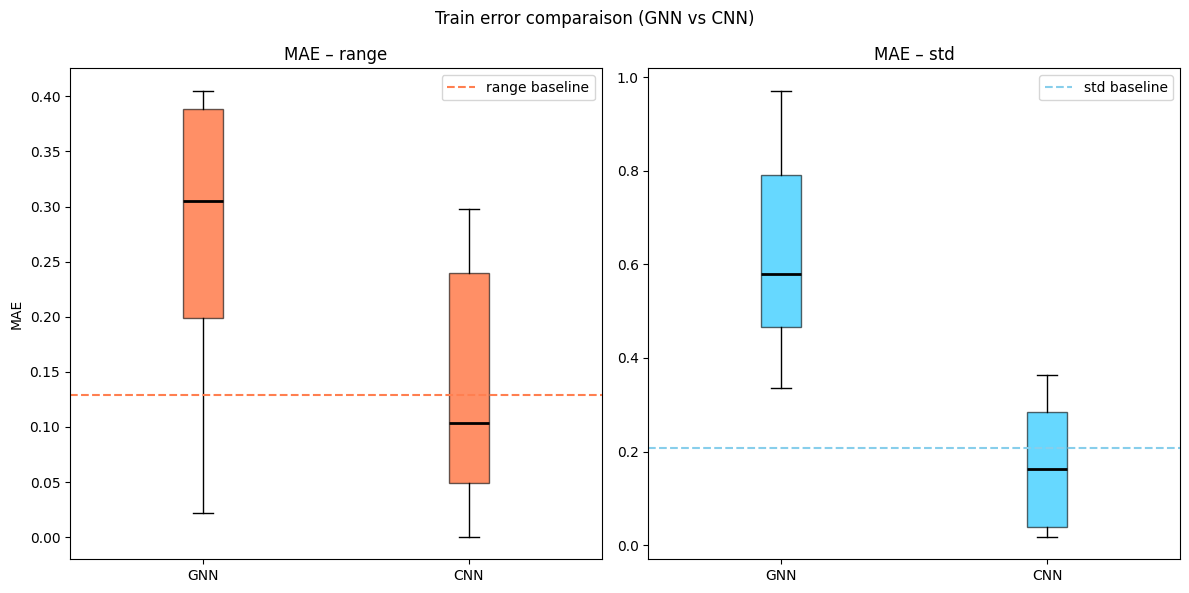

In [45]:
methods = ['GNN', 'CNN']

loss_range = [
    all_loss_train_graph[-1][:, 0],
    all_loss_train_grid[-1][:, 0],
]

loss_std = [
    all_loss_train_graph[-1][:, 1],
    all_loss_train_grid[-1][:, 1],
]

### Boxplot
fig_box_train, axs = plt.subplots(1, 2, figsize=(12, 6))

axs[0].boxplot(loss_range, labels=methods, patch_artist=True,
               boxprops=dict(facecolor='orangered', alpha=0.6), 
               medianprops=dict(linestyle='-', linewidth=2, color='black'))
axs[0].set_title("MAE – range")
axs[0].set_ylabel("MAE")

axs[1].boxplot(loss_std, labels=methods, patch_artist=True,
               boxprops=dict(facecolor='deepskyblue', alpha=0.6),
               medianprops=dict(linestyle='-', linewidth=2, color='black'))
axs[1].set_title("MAE – std")

axs[0].axhline(based[0],color='coral', ls='--', label='range baseline')
axs[1].axhline(based[1],color='skyblue', ls='--', label='std baseline')

axs[0].legend()
axs[1].legend()

plt.suptitle("Train error comparaison (GNN vs CNN)")
plt.tight_layout()
plt.show()

/tmp/ipykernel_823936/1873628417.py:20: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axs[0].boxplot(loss_range, labels=methods, patch_artist=True,
/tmp/ipykernel_823936/1873628417.py:26: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axs[1].boxplot(loss_std, labels=methods, patch_artist=True,


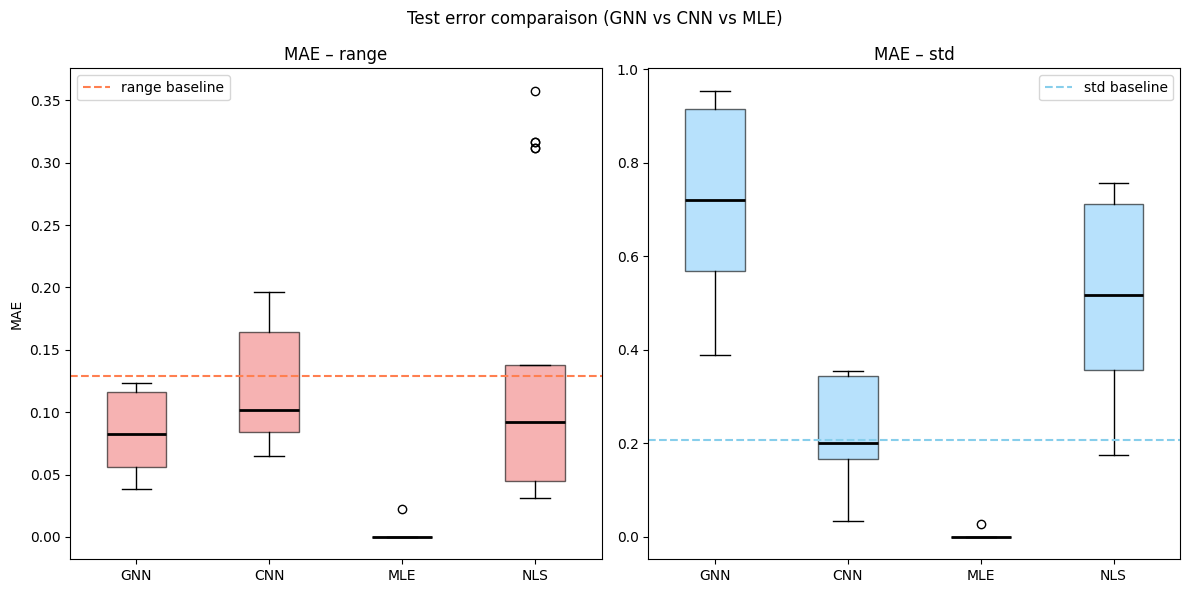

In [46]:
methods = ['GNN', 'CNN', 'MLE', 'NLS']

loss_range = [
    all_loss_test_graph[-1][:, 0],
    all_loss_test_grid[-1][:, 0],
    all_loss_test_ML[:, 0],
    all_loss_test_nls[:, 0]
]

loss_std = [
    all_loss_test_graph[-1][:, 1],
    all_loss_test_grid[-1][:, 1],
    all_loss_test_ML[:, 1],
    all_loss_test_nls[:, 1]
]

### Boxplot
fig_box_test, axs = plt.subplots(1, 2, figsize=(12, 6))

axs[0].boxplot(loss_range, labels=methods, patch_artist=True,
               boxprops=dict(facecolor='lightcoral', alpha=0.6),
               medianprops=dict(linestyle='-', linewidth=2, color='black'))
axs[0].set_title("MAE – range")
axs[0].set_ylabel("MAE")

axs[1].boxplot(loss_std, labels=methods, patch_artist=True,
               boxprops=dict(facecolor='lightskyblue', alpha=0.6),
               medianprops=dict(linestyle='-', linewidth=2, color='black'))
axs[1].set_title("MAE – std")

axs[0].axhline(based[0],color='coral', ls='--', label='range baseline')
axs[1].axhline(based[1],color='skyblue', ls='--', label='std baseline')

axs[0].legend()
axs[1].legend()

plt.suptitle("Test error comparaison (GNN vs CNN vs MLE)")
plt.tight_layout()
plt.show()

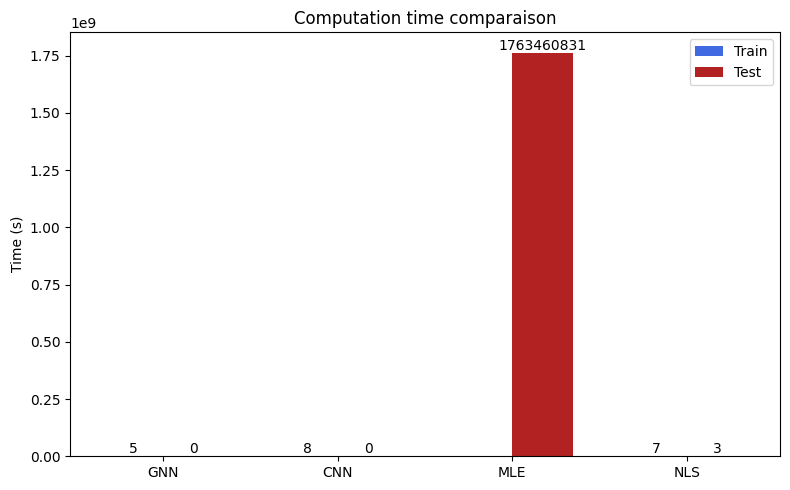

In [47]:
### Time
train_times = [time_train_graph, time_train_grid, np.nan, time_train_nls]  
test_times = [time_test_graph, time_test_grid, time_test_ML, time_test_nls]

x = np.arange(len(methods))
width = 0.35

fig_time, ax = plt.subplots(figsize=(8, 5))
bar1 = ax.bar(x - width/2, train_times, width, label='Train', color='royalblue')
bar2 = ax.bar(x + width/2, test_times, width, label='Test', color='firebrick')

for rect in bar1 + bar2:
    height = rect.get_height()
    plt.text(rect.get_x() + rect.get_width() / 2.0, height, f'{height:.0f}', ha='center', va='bottom')

ax.set_xticks(x)
ax.set_xticklabels(methods)
ax.set_ylabel("Time (s)")
ax.set_title("Computation time comparaison")
ax.legend()

plt.tight_layout()
plt.show()

In [53]:
results = {
    "all_loss_train": {
        "GNN": all_loss_train_graph,
        "CNN": all_loss_train_grid,
    },
    "all_loss_test": {
        "GNN": all_loss_test_graph,
        "CNN": all_loss_test_grid,
        "MLE": all_loss_test_ML,
        "NLS": all_loss_test_nls,
    },
    "times": {
        "time_train_graph": time_train_graph,
        "time_train_grid": time_train_grid,
        "time_test_ML": time_test_ML,
        "time_train_nls": time_train_nls,
        "time_test_nls": time_test_nls,
    },
    "meta": {
        "n_train": n_train, "m_train": m_train,
        "n_test": n_test, "m_test": m_test,
    }
}

path = f"results/{time_train_graph+time_train_grid+time_test_ML+time_train_nls+time_test_nls:.0f}time-{n_train}×{m_train}ntrain-{n_test}×{m_test}ntest" # -{n_points}npoints"

os.makedirs(path, exist_ok=True)
torch.save(results, path + "/results.pt")

In [52]:
# fig_box_train.savefig(path+"/score_train.pdf", format="pdf", bbox_inches="tight")
fig_box_train.savefig(path+"/score_train.png", format="png", bbox_inches="tight")
# fig_box_test.savefig(path+"/score_test.pdf", format="pdf", bbox_inches="tight")
fig_box_test.savefig(path+"/score_test.png", format="png", bbox_inches="tight")
# fig_time.savefig(path+"/time.pdf", format="pdf", bbox_inches="tight")
fig_time.savefig(path+"/time.png", format="png", bbox_inches="tight")

# fig_gnn.savefig(path+"/gnn.pdf", format="pdf", bbox_inches="tight")
fig_gnn.savefig(path+"/gnn_train_evolution.png", format="png", bbox_inches="tight")
# fig_cnn.savefig(path+"/cnn.pdf", format="pdf", bbox_inches="tight")
fig_cnn.savefig(path+"/cnn_train_evolution.png", format="png", bbox_inches="tight")
# fig_nls.savefig(path+"/nls.pdf", format="pdf", bbox_inches="tight")
fig_nls.savefig(path+"/nls_train_evolution.png", format="png", bbox_inches="tight")
